# Topic Relevance and Corporate Disclosure: Workflow Overview

| Item | Description |
|---|---|
| Goal | Guide a reader through the T3 section: how the legislator statements on one topic became a policy summary, how each firm's 10-K Item 1 sections became a firm-level summary, how the cosine of the two is the firm's topic relevance score, which alternatives were tried, and how the running example reaches the firms. |
| Covers | The 17 notebooks of the main chain and the running example (T3.1 to T3.5), their inputs and outputs, where the data live, and how to obtain every input again. |
| Output | None. This notebook runs no step and writes no file. |
| Run | Not applicable. The language-model steps ran in October 2026 and are not rerun. Each notebook states its own run in its header. |

T3 measures how close each S&P 500 firm's business is to what a piece of legislation regulates. The topic is consumer data privacy legislation, the primary topic of the running example's hearing. On the topic side, the 374 legislator statements that T2 placed under the topic are summarized by hearing year and then into one policy summary. On the firm side, the Item 1 (Business) section of each of the firm's 10-K filings is summarized with a focus on its lines of business, and the yearly summaries are combined into one firm-level summary. Both summaries are embedded with the same encoder, and their cosine similarity is the firm's score: one number per firm, higher when the business description is closer to the policy summary. The model is Qwen3.5-4B, run locally on one GPU; the encoder for every embedding is bge-large-en-v1.5. Nine alternative measures that change the topic side, the firm side, or both were built alongside and are kept outside the published repository.


## 1. The workflow in one figure


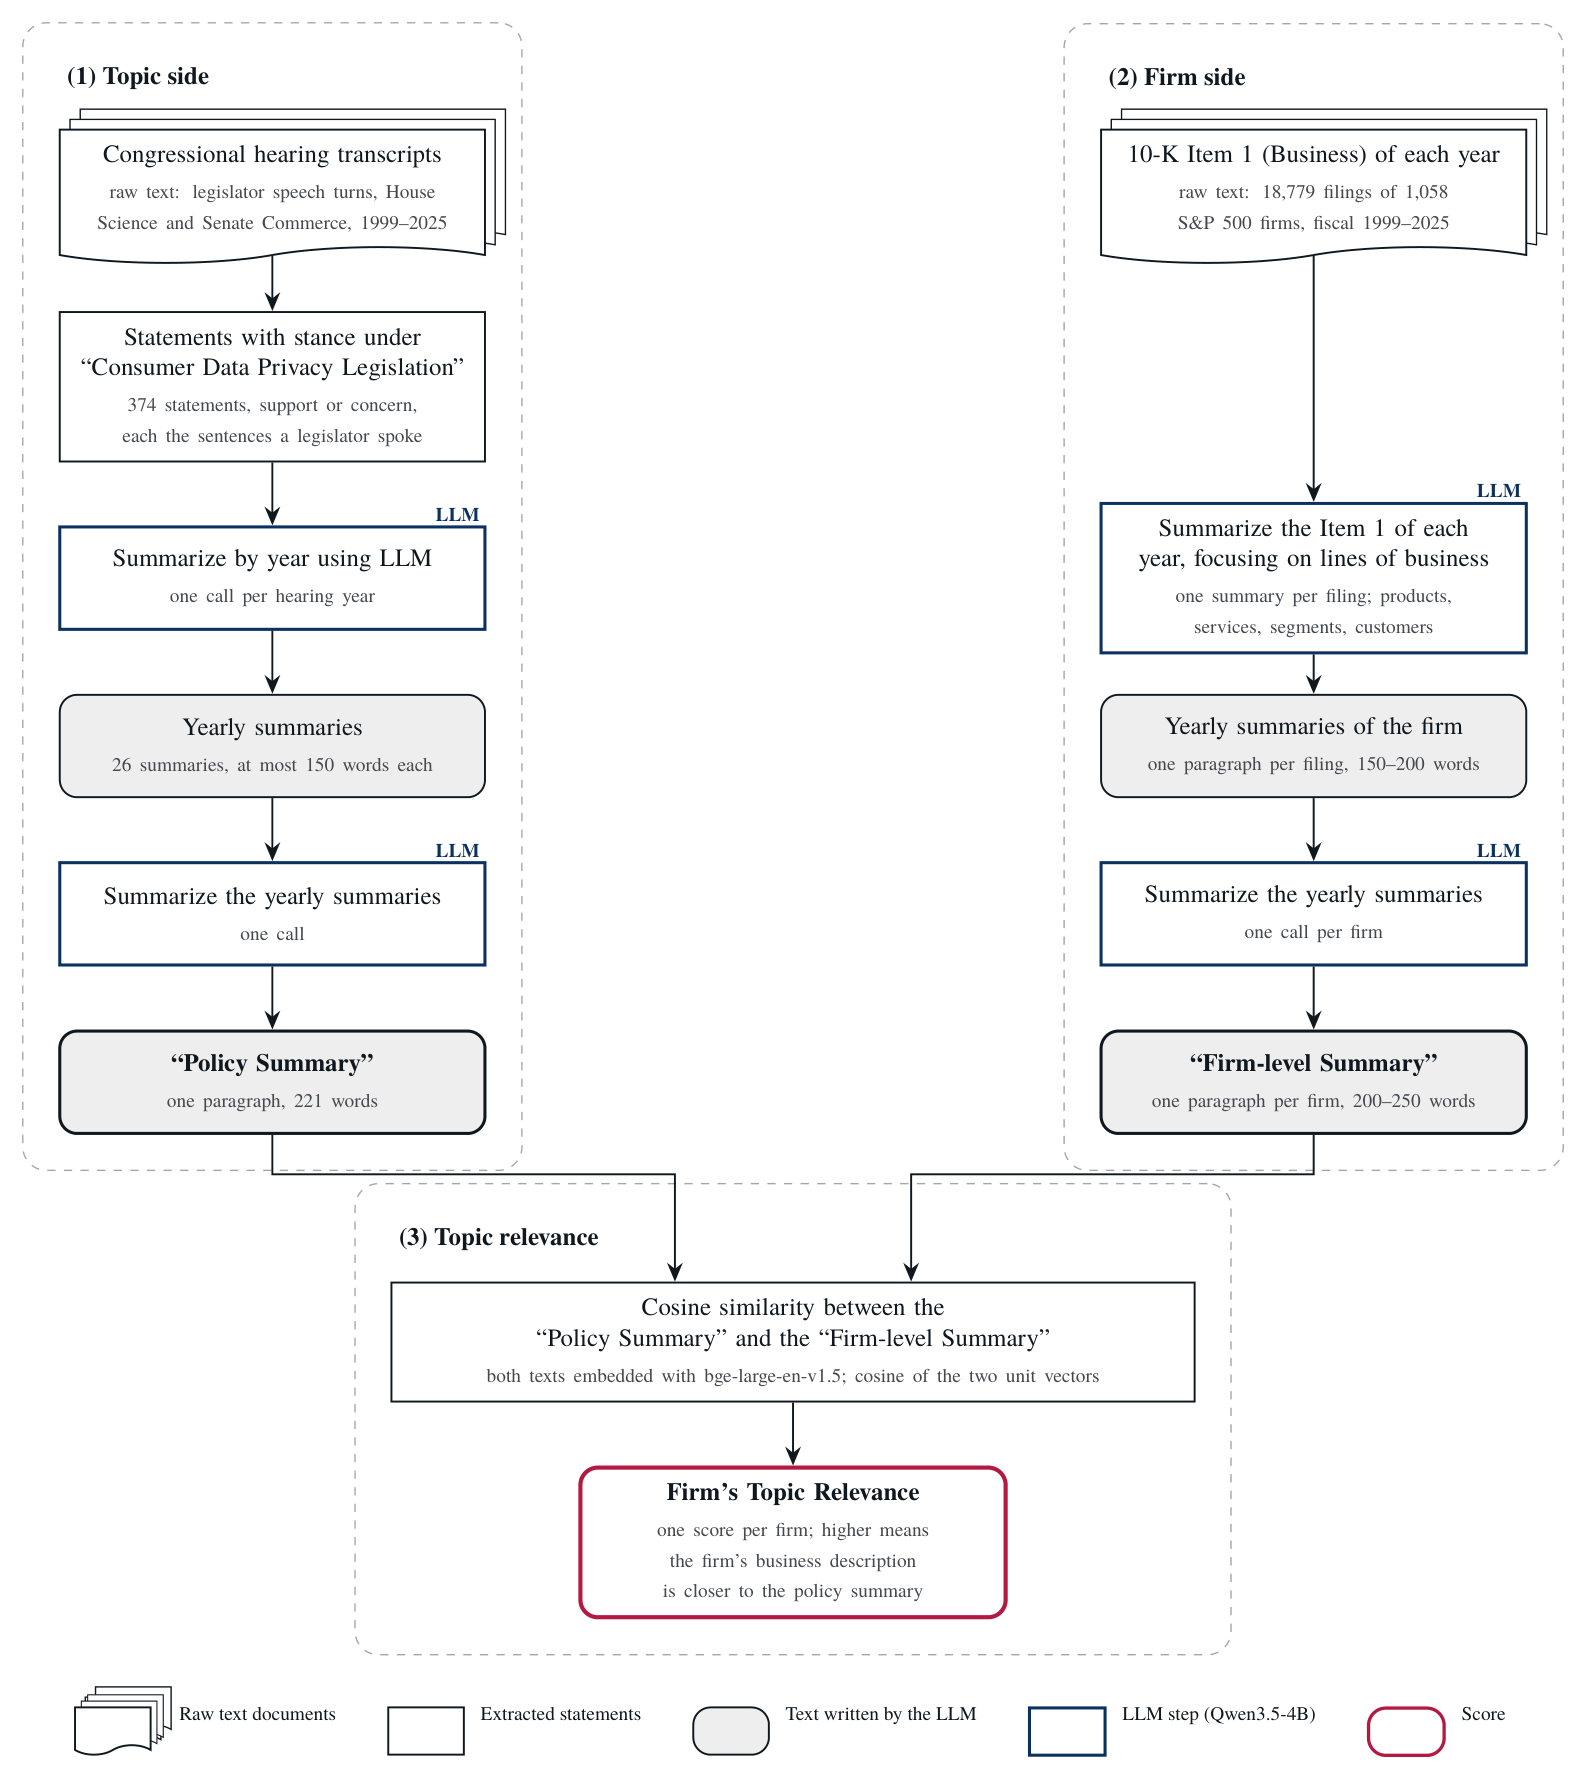

In [1]:
from IPython.display import Image, display

display(Image(filename="../../R - Results/figures/T - Three Step Text Analysis Pipeline/T3 - Topic Relevance and Corporate Disclosure/fig_topic_relevance_flowchart.png", width=900))


## 2. The main chain and its notebooks

**T3.1, the sample.** [T3.1.1 - Sample - Select the Firms and Filings](T3.1%20-%20Sample%20-%20Firms%20and%2010-K%20Item%201%20Filings/T3.1.1%20-%20Sample%20-%20Select%20the%20Firms%20and%20Filings.ipynb) keeps the S&P 500 filings with a usable Item 1 in fiscal years 1999 to 2025, one per firm and year: 18,779 filings of 1,058 firms, the all-years sample, and a three-year sample of fiscal 2010, 2015, and 2020 kept for comparison.

**T3.2, the topic side.** [T3.2.1 - Statements - Rebuild the Topic 68 Stance Statements](T3.2%20-%20Topic%20Side%20-%20Policy%20Summary%20of%20the%20Legislator%20Statements/T3.2.1%20-%20Statements%20-%20Rebuild%20the%20Topic%2068%20Stance%20Statements.ipynb) rebuilds the text of the 374 statements from the saved speech-turn sentences. [T3.2.2 - Prepare - Prompt and Yearly Statement Blocks](T3.2%20-%20Topic%20Side%20-%20Policy%20Summary%20of%20the%20Legislator%20Statements/T3.2.2%20-%20Prepare%20-%20Prompt%20and%20Yearly%20Statement%20Blocks.ipynb) writes the prompts and one block of statements per hearing year. [T3.2.3 - Production - Summarize by Year and Reduce to the Policy Summary](T3.2%20-%20Topic%20Side%20-%20Policy%20Summary%20of%20the%20Legislator%20Statements/T3.2.3%20-%20Production%20-%20Summarize%20by%20Year%20and%20Reduce%20to%20the%20Policy%20Summary.ipynb) makes 26 map calls and one reduce call and keeps the record of its October run. [T3.2.4 - Check - Trace the Policy Summary to the Statements](T3.2%20-%20Topic%20Side%20-%20Policy%20Summary%20of%20the%20Legislator%20Statements/T3.2.4%20-%20Check%20-%20Trace%20the%20Policy%20Summary%20to%20the%20Statements.ipynb) traces the summary's details back to the statements. [T3.2.5 - Embed - The Policy Summary Vector](T3.2%20-%20Topic%20Side%20-%20Policy%20Summary%20of%20the%20Legislator%20Statements/T3.2.5%20-%20Embed%20-%20The%20Policy%20Summary%20Vector.ipynb) embeds the 221-word summary.

**T3.3, the firm side.** [T3.3.1 - Prepare - Segments, Prompts, and Shards](T3.3%20-%20Firm%20Side%20-%20Summaries%20of%20the%2010-K%20Item%201%20Filings/T3.3.1%20-%20Prepare%20-%20Segments%2C%20Prompts%2C%20and%20Shards.ipynb) cuts every Item 1 into segments of at most 4,000 tokens, writes the prompts, and shards the 57,754 segments. [T3.3.2 - Production - Summarize Each Filing](T3.3%20-%20Firm%20Side%20-%20Summaries%20of%20the%2010-K%20Item%201%20Filings/T3.3.2%20-%20Production%20-%20Summarize%20Each%20Filing.ipynb) writes one paragraph per filing by map, collapse, and reduce, and [T3.3.3 - Check - Assemble the Filing Summaries](T3.3%20-%20Firm%20Side%20-%20Summaries%20of%20the%2010-K%20Item%201%20Filings/T3.3.3%20-%20Check%20-%20Assemble%20the%20Filing%20Summaries.ipynb) assembles and checks the 18,779 summaries. [T3.3.4 - Production - Summarize Each Firm](T3.3%20-%20Firm%20Side%20-%20Summaries%20of%20the%2010-K%20Item%201%20Filings/T3.3.4%20-%20Production%20-%20Summarize%20Each%20Firm.ipynb) writes one paragraph per firm from its yearly summaries, and [T3.3.5 - Check - Assemble the Firm Summaries](T3.3%20-%20Firm%20Side%20-%20Summaries%20of%20the%2010-K%20Item%201%20Filings/T3.3.5%20-%20Check%20-%20Assemble%20the%20Firm%20Summaries.ipynb) assembles and checks them. [T3.3.6 - Embed - The Filing and Firm Summary Vectors](T3.3%20-%20Firm%20Side%20-%20Summaries%20of%20the%2010-K%20Item%201%20Filings/T3.3.6%20-%20Embed%20-%20The%20Filing%20and%20Firm%20Summary%20Vectors.ipynb) embeds every summary.

**T3.4, the score and the figures.** [T3.4.1 - Score - Cosine of the Firm Summary and the Policy Summary](T3.4%20-%20Topic%20Relevance%20-%20Score%20and%20Figures/T3.4.1%20-%20Score%20-%20Cosine%20of%20the%20Firm%20Summary%20and%20the%20Policy%20Summary.ipynb) takes the cosine of each firm summary with the policy summary, attaches the firm's NAICS sector, and works Meta Platforms through as the example. [T3.4.2 - Figure - Distribution Overall and by Sector](T3.4%20-%20Topic%20Relevance%20-%20Score%20and%20Figures/T3.4.2%20-%20Figure%20-%20Distribution%20Overall%20and%20by%20Sector.ipynb) draws the distribution of the score, [T3.4.3 - Figure - Sector Means and Medians](T3.4%20-%20Topic%20Relevance%20-%20Score%20and%20Figures/T3.4.3%20-%20Figure%20-%20Sector%20Means%20and%20Medians.ipynb) the sector means and medians relative to the sample, and [T3.4.4 - Figure - Selected High and Low Relevance Firms](T3.4%20-%20Topic%20Relevance%20-%20Score%20and%20Figures/T3.4.4%20-%20Figure%20-%20Selected%20High%20and%20Low%20Relevance%20Firms.ipynb) the cases selected by the authors and the marked list of firms; the marked list is Panel B of Figure 3 of the proposal and T3.4.3's mean figure is Panel A.

**T3.5, the running example.** [T3.5.1 - Example - From the Facebook Hearing's Topic to the Firms It Concerns](T3.5%20-%20Running%20Example%20%5BFacebook-Cambridge%20Analytica%20Scandal%20Hearing%5D/T3.5.1%20-%20Example%20-%20From%20the%20Facebook%20Hearing%27s%20Topic%20to%20the%20Firms%20It%20Concerns.ipynb) follows the Facebook hearing's topic to the firms: the hearing's 13 statements among the 374, the policy summary, the selected firms' summaries, and Figure 3 as one two-panel figure. Its folder holds readable copies of the inputs, outputs, and the call log.


## 3. The alternative measures

The main measure compares two language-model summaries. Nine alternatives were built alongside it: the topic side replaced by the embedded codebook definition or by the centroid of the 374 statement embeddings, and the firm side replaced by the firm's raw Item 1 sentences (the share at or above a cosine threshold, or whether any sentence passes it) or by the mean over the yearly summaries. The summary measures agree with one another; the sentence measures agree little with them. The notebooks, their 11.6 GB of sentence embeddings, and their tables stay on the project's local copy and the scratch root and are not part of the published repository.


## 4. Where the data live

Every notebook reads and writes under the scratch root, `/scratch1/acroh/projects/LLM-Text-Analysis-and-Synthesis/T - Three Step Text Analysis Pipeline/T3 - Topic Relevance and Corporate Disclosure/`, in the subfolder of the notebook that produced the file.

| Subfolder | Processed | Interim |
|---|---|---|
| T3.1 | `filings.parquet` | |
| T3.2 | `topic68_statements.parquet`, `yearly_summaries.csv`, `policy_summary.md`, `policy_summary_meta.json`, `policy_summary_embedding.npy`, `policy_summary_text.csv` | `policy_summary_input.json`, `policy_summary_calls.jsonl` |
| T3.3 | `filing_summaries.parquet`, `firm_summaries.parquet`, the two embedding matrices with their key files, `embedding_record.json`, `token_counts.parquet` | `settings.json`, `filing_inputs/` (the segment shards), `filing_summaries/` and `firm_summaries/` (shard outputs, call logs, run records) |
| T3.4 | `firm_relevance.parquet`, `filing_cosines.parquet` | |

Figures and tables go to `R - Results/figures` and `R - Results/tables` under the same subfolder names, one folder per notebook. The flowchart above sits at the section level of `R - Results/figures`. The firm-level tables under `R - Results/tables` carry Compustat identifiers and NAICS codes. The alternative measures keep the same layout under `T3.X - Alternative Measures/` on the local copy only.


## 5. How to obtain the inputs

**The firms and their filings.** `sp500_10k_item1.parquet` and `sample_firms.parquet` are built by D3 from the SEC EDGAR 10-K archive through sec-api.io; see the D overview. **The NAICS codes.** The CRSP-Compustat link file `crsp_compustat_link.dta` is licensed WRDS data, downloaded as the D overview describes; it sits in `Raw/firm_id` of the D3 scratch folder and is never in the repository. **The statements.** `track2_assigned.parquet` and `member_turns.parquet` are built by T2.2; `codebook_v1.parquet` by T2.1; `hearings_sst.parquet` by D4. **The models.** Qwen3.5-4B and bge-large-en-v1.5 download from the Hugging Face Hub without a token; the first use writes them to `cache/huggingface` when `HF_HOME` points there. A token in `.env`, following `.env.example`, is needed only for gated models. **The hardware.** Each language-model step ran on one NVIDIA A40: the policy summary in three minutes, the filing summaries in about 51 GPU hours over two arrays of eight tasks, the firm summaries in two hours. `J - Jobs` holds the SLURM wrappers.


## 6. How to read a notebook in this section

Every notebook opens with the same table and a Run row that says when it ran and why it is or is not rerun. The three notebooks that call the language model (T3.2.3, T3.3.2, T3.3.4) keep the code of their October 2026 runs, which were launched as the scripts in `J - Jobs` describe, and end with a cell that reads the stored run records back. The embedding notebooks (T3.2.5, T3.3.6) were rerun on 2026-10-31 on one A40 and reproduce the October vectors. The notebooks that run on a CPU were rebuilt on 2026-10-31 and found identical to the October tables; the figures were redrawn in the repository's style. The prompts, the segmenter, and the checks are written out inside each notebook that uses them; there is no helper module.
